In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("ggplot")

In [3]:
dataset_path = "../dataset"

classes = ["benign","constant","random","reactive"]

In [4]:
dataframes = []

for cls in classes:

    folder = os.path.join(dataset_path,cls)

    for file in os.listdir(folder):

        path = os.path.join(folder,file)

        df = pd.read_csv(path)

        df["label"] = cls

        dataframes.append(df)

dataset = pd.concat(dataframes,ignore_index=True)

print("Dataset shape:",dataset.shape)

dataset.head()

Dataset shape: (43438, 41)


,sample,station,tx_total_pkts,tx_total_bytes,tx_ucast_pkts,tx_ucast_bytes,tx_mcast_bcast_pkts,tx_mcast_bcast_bytes,tx_failures,rx_data_pkts,...,per_antenna_noise_floor_1,per_antenna_noise_floor_2,per_antenna_noise_floor_3,per_antenna_noise_floor_4,sinr_per_antenna_1,sinr_per_antenna_2,sinr_per_antenna_3,sinr_per_antenna_4,attack,label
0,1,F8:59:71:5A:E0:3D,2153030,393147291,86357,130549343,2066673,262597948,1,20249,...,-90.0,-91.0,-89.0,-92.0,22.0,19.0,22.0,21.0,0,benign
1,2,CC:2F:71:3F:1F:24,2145730,355052289,79057,92454341,2066673,262597948,481,72819,...,-90.0,-91.0,-89.0,-92.0,18.0,26.0,16.0,17.0,0,benign
2,3,CC:2F:71:3E:C5:1F,5439387,4422565302,3372714,4159967354,2066673,262597948,502,87848,...,-90.0,-91.0,-89.0,-92.0,21.0,20.0,23.0,30.0,0,benign
3,4,F8:59:71:5A:E0:3D,2153095,393243957,86420,130645807,2066675,262598150,1,20311,...,-90.0,-91.0,-89.0,-92.0,22.0,19.0,22.0,21.0,0,benign
4,5,CC:2F:71:3F:1F:24,2145889,355255783,79214,92657633,2066675,262598150,481,72960,...,-90.0,-91.0,-89.0,-92.0,18.0,26.0,16.0,17.0,0,benign


In [5]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 43438 entries, 0 to 43437
Data columns (total 41 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   sample                                 43438 non-null  int64  
 1   station                                43438 non-null  object 
 2   tx_total_pkts                          43438 non-null  int64  
 3   tx_total_bytes                         43438 non-null  int64  
 4   tx_ucast_pkts                          43438 non-null  int64  
 5   tx_ucast_bytes                         43438 non-null  int64  
 6   tx_mcast_bcast_pkts                    43438 non-null  int64  
 7   tx_mcast_bcast_bytes                   43438 non-null  int64  
 8   tx_failures                            43438 non-null  int64  
 9   rx_data_pkts                           43438 non-null  int64  
 10  rx_data_bytes                          43438 non-null  int64  
 11  rx

In [6]:
dataset.isnull().sum()

sample                                   0
station                                  0
tx_total_pkts                            0
tx_total_bytes                           0
tx_ucast_pkts                            0
tx_ucast_bytes                           0
tx_mcast_bcast_pkts                      0
tx_mcast_bcast_bytes                     0
tx_failures                              0
rx_data_pkts                             0
rx_data_bytes                            0
rx_ucast_pkts                            0
rx_ucast_bytes                           0
rx_mcast_bcast_pkts                      0
rx_mcast_bcast_bytes                     0
rx_decrypt_succeeds                      0
tx_data_pkts_retried                     0
tx_total_pkts_sent                       0
tx_pkts_retries                          0
tx_pkts_retry_exhausted                  0
rx_total_pkts_retried                    0
rate_last_tx_pkt_min                     0
rate_last_tx_pkt_max                     0
per_antenna

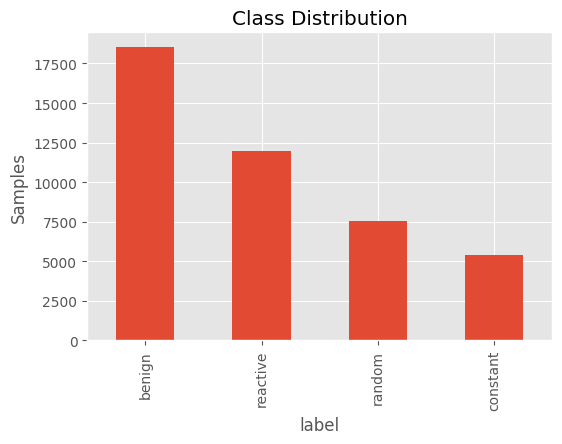

In [7]:
plt.figure(figsize=(6,4))

dataset["label"].value_counts().plot(kind="bar")

plt.title("Class Distribution")

plt.ylabel("Samples")

plt.show()

In [8]:
dataset.describe()

,sample,tx_total_pkts,tx_total_bytes,tx_ucast_pkts,tx_ucast_bytes,tx_mcast_bcast_pkts,tx_mcast_bcast_bytes,tx_failures,rx_data_pkts,rx_data_bytes,...,per_antenna_avg_rssi_rx_data_frames_4,per_antenna_noise_floor_1,per_antenna_noise_floor_2,per_antenna_noise_floor_3,per_antenna_noise_floor_4,sinr_per_antenna_1,sinr_per_antenna_2,sinr_per_antenna_3,sinr_per_antenna_4,attack
count,43438.000000,4.343800e+04,4.343800e+04,4.343800e+04,4.343800e+04,4.343800e+04,4.343800e+04,43438.000000,4.343800e+04,4.343800e+04,...,43438.000000,43438.000000,43438.000000,43438.000000,43438.00000,43438.000000,43438.000000,43438.000000,43438.000000,43438.000000
mean,4276.677632,3.902540e+06,1.842307e+09,1.101182e+06,1.487918e+09,2.801358e+06,3.543888e+08,200.574658,2.742955e+05,2.633346e+08,...,-63.509439,-86.566186,-90.000875,-85.543326,-89.13822,20.165017,24.446360,21.047838,25.335628,0.573185
std,3967.812587,1.575196e+06,2.233471e+09,1.602280e+06,2.253196e+09,7.534098e+05,9.421285e+07,349.840526,3.719873e+05,3.667478e+08,...,8.354024,4.628912,2.988070,4.699708,3.78807,10.246940,10.609642,10.961309,8.434851,0.494621
min,1.000000,2.145730e+06,2.727062e+08,1.700000e+01,2.179000e+03,2.066673e+06,2.625979e+08,0.000000,5.700000e+01,5.353000e+03,...,-79.000000,-91.000000,-94.000000,-91.000000,-94.00000,1.000000,1.000000,1.000000,2.000000,0.000000
25%,1358.000000,2.721057e+06,4.868904e+08,1.140900e+04,6.198650e+06,2.083930e+06,2.646950e+08,1.000000,2.026025e+04,3.734399e+06,...,-70.000000,-90.000000,-92.000000,-89.000000,-93.00000,14.000000,18.000000,13.000000,19.000000,0.000000
50%,2896.000000,3.756251e+06,6.935744e+08,2.741315e+05,3.791955e+08,2.627650e+06,3.326367e+08,6.000000,9.141200e+04,3.503596e+07,...,-68.000000,-89.000000,-91.000000,-88.000000,-90.00000,18.000000,21.000000,19.000000,23.000000,1.000000
75%,5952.000000,4.794516e+06,1.910040e+09,1.243657e+06,1.581269e+09,3.757241e+06,4.739103e+08,481.000000,3.910328e+05,4.574933e+08,...,-60.000000,-83.000000,-88.000000,-81.000000,-85.00000,23.000000,28.000000,24.000000,31.000000,1.000000
max,15531.000000,1.013974e+07,1.098906e+10,6.919349e+06,1.058230e+10,3.853266e+06,4.859505e+08,2222.000000,1.576528e+06,1.364120e+09,...,-36.000000,-71.000000,-79.000000,-71.000000,-75.00000,52.000000,58.000000,55.000000,56.000000,1.000000


In [9]:
plt.figure(figsize=(6,4))

sns.histplot(dataset["rssi"],bins=50)

plt.title("RSSI Distribution")

plt.show()

KeyError: 'rssi'

<Figure size 600x400 with 0 Axes>

In [ ]:
plt.figure(figsize=(10,8))

corr = dataset.corr(numeric_only=True)

sns.heatmap(corr,annot=False,cmap="coolwarm")

plt.title("Feature Correlation Matrix")

plt.show()

In [ ]:
selected_features = [
"tx_total_pkts",
"tx_failures",
"tx_pkts_retries",
"rx_data_pkts",
"rx_total_pkts_retried",
"tx_total_pkts_sent",
"per_antenna_avg_rssi_rx_data_frames_1",
"per_antenna_avg_rssi_rx_data_frames_2",
"per_antenna_noise_floor_1",
"per_antenna_noise_floor_2",
"sinr_per_antenna_1",
"sinr_per_antenna_2"
]

X = dataset[selected_features]
y = dataset["label"]

In [ ]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()

y_encoded = encoder.fit_transform(y)

print("Classes:",encoder.classes_)

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Scaled features shape:",X_scaled.shape)

In [ ]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test = train_test_split(
    X_scaled,
    y_encoded,
    test_size=0.2,
    random_state=42
)

print("Train shape:",X_train.shape)
print("Test shape:",X_test.shape)

In [ ]:
sample = X_train[0]

print("Feature vector sent to FPGA:")

sample

In [ ]:
np.save("../dataset/sample_data/X_train.npy",X_train)
np.save("../dataset/sample_data/y_train.npy",y_train)

np.save("../dataset/sample_data/X_test.npy",X_test)
np.save("../dataset/sample_data/y_test.npy",y_test)

print("Preprocessed dataset saved")

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(x="label",y="snr",data=dataset)

plt.title("SNR distribution across classes")

plt.show()